Movi Lns



In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split, StratifiedKFold

In [3]:
calificaciones = pd.read_csv("ml-latest-small/ratings.csv")
peliculas = pd.read_csv("ml-latest-small/movies.csv")
titulo = peliculas.set_index("movieId")["title"]   # para traducir movieId → título

In [4]:
peliculas.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
calificaciones.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [6]:
n_usuarios = calificaciones["userId"].nunique()
n_peliculas = calificaciones["movieId"].nunique()
print("Calificaciones:", len(calificaciones))
print("Usuarios:", n_usuarios)
print("Películas con al menos una calificación:", n_peliculas)
print(f"Celdas llenas de la tabla usuario × película: {len(calificaciones) / (n_usuarios * n_peliculas):.1%}")

Calificaciones: 100836
Usuarios: 610
Películas con al menos una calificación: 9724
Celdas llenas de la tabla usuario × película: 1.7%


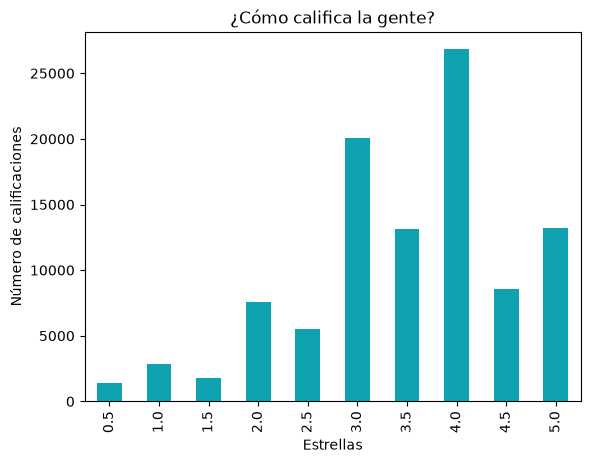

In [7]:
calificaciones["rating"].value_counts().sort_index().plot(kind="bar", color="#0FA3B1")
plt.title("¿Cómo califica la gente?")
plt.xlabel("Estrellas")
plt.ylabel("Número de calificaciones")
plt.show()

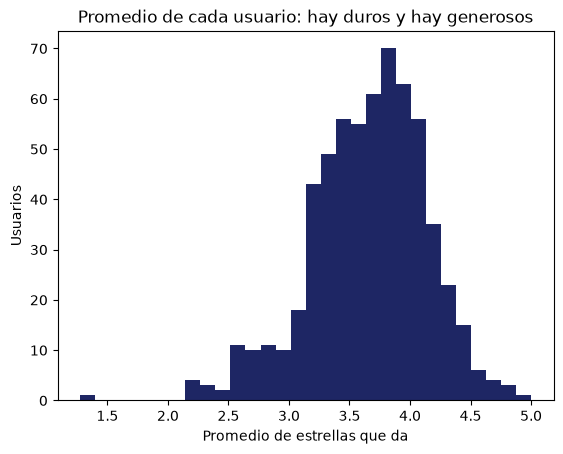

userId
442    1.275000
139    2.144330
508    2.145833
153    2.217877
567    2.245455
         ...   
30     4.735294
25     4.807692
515    4.846154
251    4.869565
53     5.000000
Name: rating, Length: 610, dtype: float64

In [8]:
promedio_por_usuario = calificaciones.groupby("userId")["rating"].mean()
promedio_por_usuario.plot(kind="hist", bins=30, color="#1E2664")
plt.title("Promedio de cada usuario: hay duros y hay generosos")
plt.xlabel("Promedio de estrellas que da")
plt.ylabel("Usuarios")
plt.show()
promedio_por_usuario.sort_values()

In [9]:
conteo = calificaciones["movieId"].value_counts()   # calificaciones por película
print("Películas con UNA sola calificación:", (conteo == 1).sum())
print("Mediana de calificaciones por película:", conteo.median())
print("Mediana de calificaciones por película:", conteo.mean())

Películas con UNA sola calificación: 3446
Mediana de calificaciones por película: 3.0
Mediana de calificaciones por película: 10.369806663924312


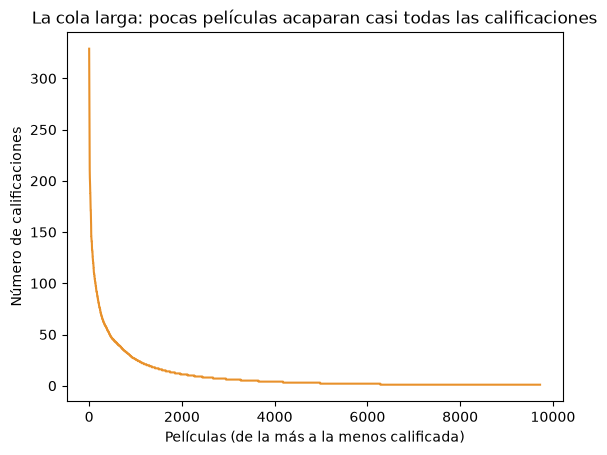

El 10 % más visto de las películas se lleva el 60% de las calificaciones


In [10]:
# ⌨️
plt.plot(conteo.values, color="#E8912B")
plt.title("La cola larga: pocas películas acaparan casi todas las calificaciones")
plt.xlabel("Películas (de la más a la menos calificada)")
plt.ylabel("Número de calificaciones")
plt.show()
top10 = int(len(conteo) * 0.10)
print(f"El 10 % más visto de las películas se lleva el {conteo.head(top10).sum() / conteo.sum():.0%} de las calificaciones")

incluyendo reseña


In [11]:
lista = [1, 3114, 78499, 4886, 6377, 8961, 50872, 68954, 60069, 4306, 364, 588, 5618, 134853, 152081, 106696,
         2571, 260, 1196, 4993, 5952, 7153, 4896, 6539, 480, 1270, 79132, 109487, 72998, 58559, 59315, 89745, 112852, 122904,
         356, 318, 1721, 8533, 3578, 296, 2959, 593, 858, 47, 48516,
         69122, 54503, 7451, 1258, 1997, 1407, 8957, 5679]
pd.set_option("display.max_rows", 60)
peliculas.set_index("movieId").loc[lista, ["title", "genres"]]

,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX
4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy
6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy
8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy
50872,Ratatouille (2007),Animation|Children|Drama
68954,Up (2009),Adventure|Animation|Children|Drama
60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi


In [ ]:
mis_calificaciones = {
    1: 2,        # Toy Story
    54503: 4,     # Superbad
    68954: 5,  # Up
    47: 5,  # Seven
    4306: 2.5,     # Shrek
    364: 4,    # The Lion King
    109487: 5,     # Interstellar 
    260: 4,    # Star Wars IV
    79132: 5,  # Inception
    2959: 5,     # Fight Club

}
mi_perfil = pd.DataFrame({"userId": 0,
                        "movieId": list(mis_calificaciones.keys()),
                        "rating": list(mis_calificaciones.values())})
print("Calificaste", len(mi_perfil), "películas. Tu promedio:", round(mi_perfil["rating"].mean(), 2))

Calificaste 10 películas. Tu promedio: 4.15


In [14]:
del calificaciones["timestamp"]   # timestamp no nos sirve

In [ ]:
calificaciones 

,userId,movieId,rating
0,1,1,4.0
1,1,3,4.0
2,1,6,4.0
3,1,47,5.0
4,1,50,5.0
...,...,...,...
100831,610,166534,4.0
100832,610,168248,5.0
100833,610,168250,5.0
100834,610,168252,5.0


In [16]:
mi_perfil

,userId,movieId,rating
0,0,1,2.0
1,0,54503,4.0
2,0,68954,5.0
3,0,47,5.0
4,0,4306,2.5
5,0,364,4.0
6,0,109487,5.0
7,0,260,4.0
8,0,79132,5.0
9,0,2959,5.0


In [18]:
todas = pd.concat([calificaciones, mi_perfil], ignore_index=True)

In [19]:
todas

,userId,movieId,rating
0,1,1,4.0
1,1,3,4.0
2,1,6,4.0
3,1,47,5.0
4,1,50,5.0
...,...,...,...
100841,0,364,4.0
100842,0,109487,5.0
100843,0,260,4.0
100844,0,79132,5.0


Recomendacion Usuario 

In [21]:
populares = conteo[conteo >= 20].index
datos = todas[todas["movieId"].isin(populares)]
print("Películas que conservamos:", len(populares))
print(f"Calificaciones que conservamos: {len(datos) / len(todas):.0%}")

Películas que conservamos: 1297
Calificaciones que conservamos: 67%


In [22]:
resumen = datos.groupby("userId")["rating"].agg(["count", "std"])
resumen[resumen["std"] == 0]

,count,std
userId,,
53,14,0.0


In [23]:
usuarios_validos = resumen[(resumen["count"] >= 10) & (resumen["std"] > 0)].index
datos = datos[datos["userId"].isin(usuarios_validos)]
print("Usuarios que conservamos:", datos["userId"].nunique())
print("¿Sigues tú en los datos?", 0 in usuarios_validos)

Usuarios que conservamos: 608
¿Sigues tú en los datos? True


In [24]:
datos

,userId,movieId,rating
0,1,1,4.0
1,1,3,4.0
2,1,6,4.0
3,1,47,5.0
4,1,50,5.0
...,...,...,...
100841,0,364,4.0
100842,0,109487,5.0
100843,0,260,4.0
100844,0,79132,5.0


In [25]:
tabla = datos.pivot_table(index="userId", columns="movieId", values="rating")
print("Forma de la tabla:", tabla.shape)
print(f"Celdas vacías: {tabla.isna().mean().mean():.1%}")
tabla.iloc[:8, :8]

Forma de la tabla: (608, 1297)
Celdas vacías: 91.4%


movieId,1,2,3,5,6,7,10,11
userId,,,,,,,,
0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4.0,NaN,4.0,NaN,4.0,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,5.0,4.0,4.0,3.0,4.0
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


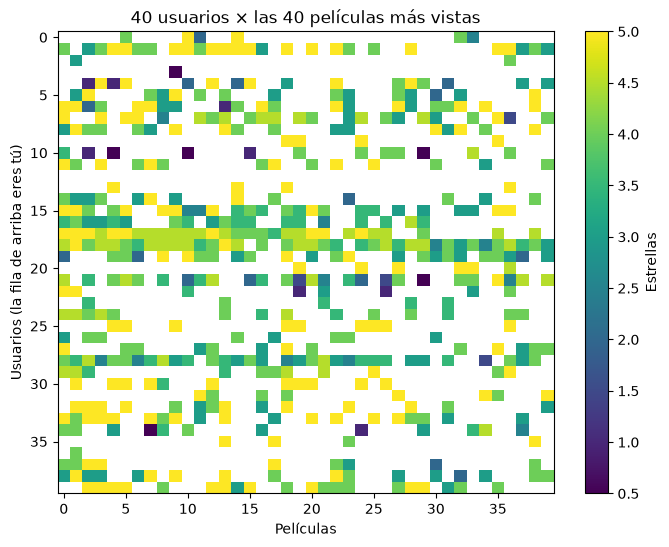

In [26]:
mas_vistas = tabla.count().sort_values(ascending=False).index[:40]
muestra = tabla.loc[tabla.index[:40], mas_vistas]
plt.figure(figsize=(8, 6))
plt.imshow(muestra, cmap="viridis", aspect="auto")
plt.colorbar(label="Estrellas")
plt.title("40 usuarios × las 40 películas más vistas")
plt.xlabel("Películas")
plt.ylabel("Usuarios (la fila de arriba eres tú)")
plt.show()

In [27]:
muestra

movieId,356,318,296,593,2571,260,480,110,589,527,...,380,32,364,4306,377,1270,3578,1580,590,648
userId,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,4.0,2.5,NaN,NaN,NaN,NaN,NaN,NaN
1,4.0,NaN,3.0,4.0,5.0,5.0,4.0,4.0,NaN,5.0,...,NaN,NaN,NaN,NaN,NaN,5.0,5.0,3.0,4.0,3.0
2,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,1.0,5.0,1.0,5.0,NaN,NaN,NaN,NaN,...,NaN,2.0,NaN,NaN,NaN,NaN,NaN,3.0,NaN,3.0
5,NaN,3.0,5.0,NaN,NaN,NaN,NaN,4.0,3.0,5.0,...,2.0,NaN,3.0,NaN,NaN,NaN,NaN,NaN,5.0,NaN
6,5.0,5.0,2.0,4.0,NaN,NaN,5.0,5.0,3.0,3.0,...,4.0,4.0,5.0,NaN,5.0,NaN,NaN,NaN,5.0,NaN
7,5.0,NaN,NaN,5.0,NaN,5.0,5.0,NaN,2.5,NaN,...,3.0,NaN,NaN,4.0,NaN,5.0,1.5,NaN,NaN,4.0
8,3.0,5.0,4.0,4.0,NaN,NaN,4.0,3.0,NaN,5.0,...,5.0,3.0,5.0,NaN,4.0,NaN,NaN,NaN,5.0,NaN


Calificaciones en el promedio

In [28]:
promedio = tabla.mean(axis=1)                 # promedio de cada usuario
centrada = tabla.sub(promedio, axis=0)        # calificación − su promedio
centrada = centrada.fillna(0)                 # hueco = sin opinión
centrada.loc[0, list(mis_calificaciones)].round(2)   # tus gustos, ya centrados

movieId
1        -2.15
54503    -0.15
68954     0.85
47        0.85
4306     -1.65
364      -0.15
109487    0.85
260      -0.15
79132     0.85
2959      0.85
Name: 0, dtype: float64

Filtrado Colaborativo Us - Us 

In [30]:
knn_usuarios = NearestNeighbors(metric="cosine")
knn_usuarios.fit(centrada)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [31]:
distancias, posiciones = knn_usuarios.kneighbors(centrada.loc[[0]], n_neighbors=11)
vecinos = pd.DataFrame({"usuario": centrada.index[posiciones[0]],
                        "similitud": (1 - distancias[0]).round(3)})
vecinos
 

,usuario,similitud
0,0,1.000
1,544,0.293
2,550,0.283
3,598,0.246
4,601,0.222
5,62,0.220
6,491,0.210
7,193,0.180
8,90,0.179
9,76,0.176


In [33]:
vecino_uno = vecinos["usuario"].iloc[1]
comparacion = tabla.loc[[0, vecino_uno]].T.dropna()
comparacion.index = titulo[comparacion.index]
comparacion

userId,0,544
title,,
Toy Story (1995),2.0,3.0


Vcinos a rcomndacions

In [34]:
def recomendar_usuario_usuario(usuario, k=30, min_vecinos=5, n=10):
    # 1) Los k vecinos más parecidos (el primero es el propio usuario: lo quitamos)
    distancias, posiciones = knn_usuarios.kneighbors(centrada.loc[[usuario]], n_neighbors=k + 1)
    vecinos = centrada.index[posiciones[0][1:]]
    similitud = pd.Series(1 - distancias[0][1:], index=vecinos)

    # 2) Opinión de los vecinos sobre cada película, ponderada por su similitud
    opinion = centrada.loc[vecinos].mul(similitud, axis=0).sum()
    vieron = tabla.loc[vecinos].notna()
    peso = vieron.mul(similitud.abs(), axis=0).sum()
    cuantos = vieron.sum()

    # 3) Predicción = tu promedio + opinión de tus vecinos (sin pasarse de 0.5 a 5 estrellas)
    prediccion = (promedio[usuario] + opinion / peso).clip(0.5, 5)

    # 4) Solo películas que NO has visto y que vieron al menos min_vecinos de tus vecinos
    candidatas = tabla.loc[usuario].isna() & (cuantos >= min_vecinos)
    resultado = pd.DataFrame({"pelicula": titulo[prediccion[candidatas].index].values,
                              "estrellas_predichas": prediccion[candidatas].round(2).values,
                              "vecinos_que_la_vieron": cuantos[candidatas].values})
    return resultado.sort_values("estrellas_predichas", ascending=False).head(n).reset_index(drop=True)
 

In [35]:
 recomendar_usuario_usuario(0)

,pelicula,estrellas_predichas,vecinos_que_la_vieron
0,"Usual Suspects, The (1995)",5.00,5
1,Fargo (1996),5.00,6
2,"Green Mile, The (1999)",5.00,6
3,Harry Potter and the Chamber of Secrets (2002),4.99,6
4,Spirited Away (Sen to Chihiro no kamikakushi) ...,4.87,5
5,"Godfather, The (1972)",4.86,8
6,Harry Potter and the Order of the Phoenix (2007),4.85,7
7,Pulp Fiction (1994),4.84,11
8,Alien (1979),4.83,5
9,Reservoir Dogs (1992),4.79,7


Filtrado Colaborativo Itm - Itm 

In [36]:
por_pelicula = centrada.T                    # filas = películas, columnas = usuarios
knn_peliculas = NearestNeighbors(metric="cosine")
knn_peliculas.fit(por_pelicula)
por_pelicula.shape

(1297, 608)

In [37]:
def parecidas(movie_id, n=10):
    distancias, posiciones = knn_peliculas.kneighbors(por_pelicula.loc[[movie_id]], n_neighbors=n + 1)
    ids = por_pelicula.index[posiciones[0][1:]]          # quitamos a la propia película
    return pd.DataFrame({"pelicula": titulo[ids].values,
                         "similitud": (1 - distancias[0][1:]).round(2)})

print("Parecidas a:", titulo[1])
parecidas(1)

Parecidas a: Toy Story (1995)


,pelicula,similitud
0,Toy Story 2 (1999),0.35
1,Aladdin (1992),0.28
2,Toy Story 3 (2010),0.27
3,Wallace & Gromit: The Wrong Trousers (1993),0.26
4,"Incredibles, The (2004)",0.22
5,Finding Nemo (2003),0.22
6,Blazing Saddles (1974),0.21
7,Back to the Future (1985),0.21
8,Babe (1995),0.20
9,"Lion King, The (1994)",0.19


In [38]:
print(f'Peliculas parecidas a: {titulo[50872]}')
parecidas(50872)

Peliculas parecidas a: Ratatouille (2007)


,pelicula,similitud
0,How to Train Your Dragon (2010),0.27
1,The Lego Movie (2014),0.27
2,"Monsters, Inc. (2001)",0.25
3,Arrival (2016),0.23
4,Iron Man (2008),0.22
5,Finding Nemo (2003),0.21
6,"Hangover, The (2009)",0.20
7,"Grand Budapest Hotel, The (2014)",0.19
8,"Incredibles, The (2004)",0.19
9,"Perks of Being a Wallflower, The (2012)",0.19


In [39]:
K_MAX = 200
dist_peliculas, pos_peliculas = knn_peliculas.kneighbors(n_neighbors=K_MAX)  # vecinas de TODAS (sin sí mismas)

def recomendar_item_item(usuario, k=30, min_vistas=3, n=10):
    mis_notas = centrada.loc[usuario]          # tus calificaciones centradas
    vistas = tabla.loc[usuario].notna()        # películas que ya viste
    filas = []
    for i, pelicula in enumerate(por_pelicula.index):
        if vistas[pelicula]:
            continue                            # ya la viste: no se recomienda
        vecinas = por_pelicula.index[pos_peliculas[i, :k]]
        similitud = 1 - dist_peliculas[i, :k]
        ok = vistas[vecinas].values             # ¿cuáles de sus vecinas viste tú?
        if ok.sum() < min_vistas:
            continue
        pred = promedio[usuario] + (similitud[ok] @ mis_notas[vecinas].values[ok]) / np.abs(similitud[ok]).sum()
        filas.append((titulo[pelicula], round(min(max(pred, 0.5), 5), 2), int(ok.sum())))
    resultado = pd.DataFrame(filas, columns=["pelicula", "estrellas_predichas", "vecinas_que_viste"])
    return resultado.sort_values("estrellas_predichas", ascending=False).head(n).reset_index(drop=True)

In [40]:
# Las dos listas lado a lado
uu = recomendar_usuario_usuario(0)
ii = recomendar_item_item(0)
pd.DataFrame({"usuario-usuario": uu["pelicula"], "ítem-ítem": ii["pelicula"]})

,usuario-usuario,ítem-ítem
0,"Usual Suspects, The (1995)",Gran Torino (2008)
1,Fargo (1996),Kingsman: The Secret Service (2015)
2,"Green Mile, The (1999)",Django Unchained (2012)
3,Harry Potter and the Chamber of Secrets (2002),"Matrix, The (1999)"
4,Spirited Away (Sen to Chihiro no kamikakushi) ...,"Usual Suspects, The (1995)"
5,"Godfather, The (1972)","Departed, The (2006)"
6,Harry Potter and the Order of the Phoenix (2007),Saving Private Ryan (1998)
7,Pulp Fiction (1994),"Godfather, The (1972)"
8,Alien (1979),Forrest Gump (1994)
9,Reservoir Dogs (1992),"Lord of the Rings: The Return of the King, The..."
